# Exploratory Data Analysis and Visualization
This notebook creates the required scatter plots, bar charts and yearly trend using the IBM course dataset. All charts are generated from loaded data; written findings should be based on the resulting figures.

In [3]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Load the cleaned dataset created by data_wrangling.ipynb
df = pd.read_csv("spacex_cleaned.csv")

# Standardize column names for visualization
column_mapping = {
    "Flight_Number": "FlightNumber",
    "PAYLOAD_MASS__KG_": "PayloadMass",
    "Payload_Mass": "PayloadMass",
    "Launch_Site": "LaunchSite",
}

df = df.rename(columns=column_mapping)

# Confirm required columns
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

required = ["FlightNumber", "PayloadMass", "LaunchSite", "Orbit", "Class"]
missing = [col for col in required if col not in df.columns]

if missing:
    raise KeyError(f"Missing columns: {missing}")

display(df.head())


Dataset shape: (101, 12)
Columns: ['Date', 'Time (UTC)', 'Booster_Version', 'LaunchSite', 'Payload', 'PayloadMass', 'Orbit', 'Customer', 'Mission_Outcome', 'Landing_Outcome', 'FlightNumber', 'Class']


,Date,Time (UTC),Booster_Version,LaunchSite,Payload,PayloadMass,Orbit,Customer,Mission_Outcome,Landing_Outcome,FlightNumber,Class
0,2010-06-04,18:45:00,F9 v1.0 B0003,CCAFS LC-40,Dragon Spacecraft Qualification Unit,0,LEO,SpaceX,Success,Failure (parachute),1,0
1,2010-12-08,15:43:00,F9 v1.0 B0004,CCAFS LC-40,"Dragon demo flight C1, two CubeSats, barrel of...",0,LEO (ISS),NASA (COTS) NRO,Success,Failure (parachute),2,0
2,2012-05-22,7:44:00,F9 v1.0 B0005,CCAFS LC-40,Dragon demo flight C2,525,LEO (ISS),NASA (COTS),Success,No attempt,3,0
3,2012-10-08,0:35:00,F9 v1.0 B0006,CCAFS LC-40,SpaceX CRS-1,500,LEO (ISS),NASA (CRS),Success,No attempt,4,0
4,2013-03-01,15:10:00,F9 v1.0 B0007,CCAFS LC-40,SpaceX CRS-2,677,LEO (ISS),NASA (CRS),Success,No attempt,5,0


## 1. Flight number versus landing outcome

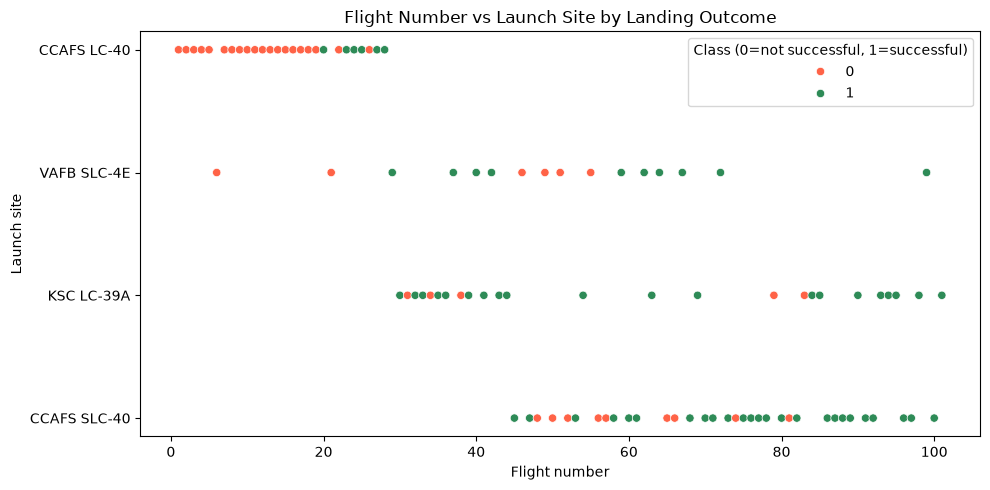

In [4]:
plt.figure(figsize=(10, 5))
sns.scatterplot(data=df, x="FlightNumber", y="LaunchSite", hue="Class", palette={0:"tomato", 1:"seagreen"})
plt.title("Flight Number vs Launch Site by Landing Outcome")
plt.xlabel("Flight number")
plt.ylabel("Launch site")
plt.legend(title="Class (0=not successful, 1=successful)")
plt.tight_layout()
plt.savefig("eda_flightnumber_launchsite.png", dpi=160)
plt.show()

## 2. Payload mass versus landing outcome

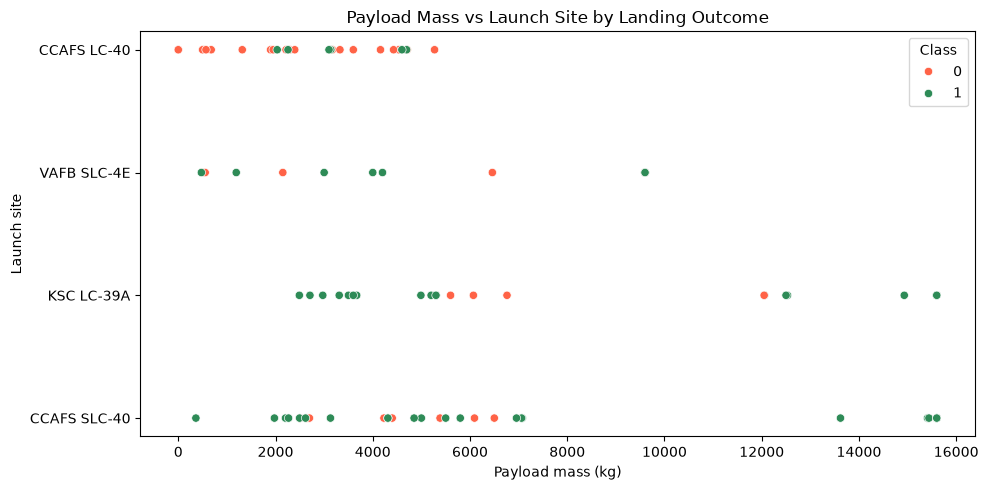

In [5]:
plt.figure(figsize=(10, 5))
sns.scatterplot(data=df, x="PayloadMass", y="LaunchSite", hue="Class", palette={0:"tomato", 1:"seagreen"})
plt.title("Payload Mass vs Launch Site by Landing Outcome")
plt.xlabel("Payload mass (kg)")
plt.ylabel("Launch site")
plt.tight_layout()
plt.savefig("eda_payload_launchsite.png", dpi=160)
plt.show()

## 3. Landing success rate by orbit

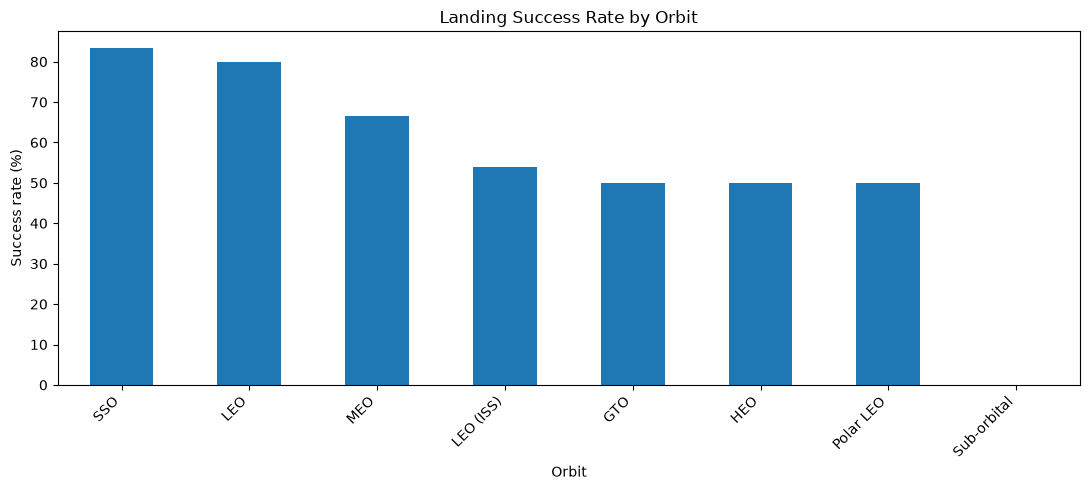

,success_rate_percent
Orbit,
SSO,83.33
LEO,80.00
MEO,66.67
LEO (ISS),53.85
GTO,50.00
HEO,50.00
Polar LEO,50.00
Sub-orbital,0.00


In [6]:
orbit_rate = df.groupby("Orbit", dropna=False)["Class"].mean().mul(100).sort_values(ascending=False)
plt.figure(figsize=(11, 5))
orbit_rate.plot(kind="bar")
plt.title("Landing Success Rate by Orbit")
plt.xlabel("Orbit")
plt.ylabel("Success rate (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("eda_success_by_orbit.png", dpi=160)
plt.show()
display(orbit_rate.to_frame("success_rate_percent").round(2))

## 4. Yearly landing success trend

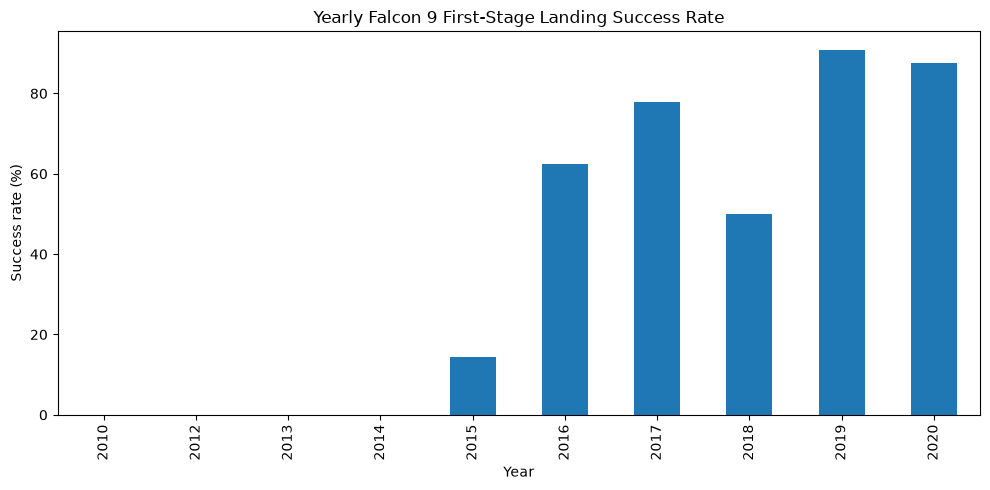

,success_rate_percent
Year,
2010,0.00
2012,0.00
2013,0.00
2014,0.00
2015,14.29
2016,62.50
2017,77.78
2018,50.00
2019,90.91


In [8]:

# Convert Date to datetime format
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# Extract year and calculate yearly success rate
df["Year"] = df["Date"].dt.year

year_rate = (
    df.dropna(subset=["Year"])
      .groupby("Year")["Class"]
      .mean()
      .mul(100)
)

# Plot yearly success trend
plt.figure(figsize=(10, 5))
year_rate.plot(kind="bar")

plt.title("Yearly Falcon 9 First-Stage Landing Success Rate")
plt.xlabel("Year")
plt.ylabel("Success rate (%)")
plt.tight_layout()

plt.savefig("eda_yearly_success_rate.png", dpi=160)
plt.show()

display(year_rate.to_frame("success_rate_percent").round(2))


## How to write findings
After running the notebook, write 2–4 sentences based on the displayed charts. Mention sample size or missing data where relevant. Avoid claiming that a variable causes landing success: these are observational relationships, not causal tests.